# INF201 – Deliverable 3: A mini-RPG battle simulator

**Authors:** Mathias Gundersen & Jakub Mermer
**GitHub repository:** https://github.com/saltonese/Del_3-G6_5.git

In this notebook we present the classes that make up our battle simulator, and use them to simulate battles between different types of characters, with and without weapons. The reusable code lives in separate modules; the notebook is only used for presentation and experiments.

| Module | Classes | Purpose |
|---|---|---|
| `dice.py` | `Dice` | Randomness: an n-sided dice |
| `items.py` | `Weapon` | Items a character can hold; the damage is decided by a dice |
| `character.py` | `Character`, `Warrior`, `Mage` | The characters, with the specialisations as subclasses |
| `battle.py` | `Battle` | Turn-based combat between two characters |

How the classes relate to each other (an arrow means "is used by" or "is the parent of"):

```
Dice --> Weapon --> Character --> Warrior, Mage
                        |
                        v
                 Battle(hero, enemy)
```

- **Composition** : a `Weapon` has a `Dice`, and a `Character` has a `Weapon`.
- **Inheritance** : `Warrior` and `Mage` are specialised `Character`s.
- A `Battle` *uses* two `Character` objects, and works with any subclass thanks to the shared public interface (`attack()`, `is_alive`, `hp`, ...).

## Setup

All random behaviour goes through Python's `random` module, so we seed it to make the results reproducible. The helper `show_class()` prints an overview of a class (constructor, attributes, properties and methods) and marks what is inherited; we use it to present each class below.

In [59]:
import inspect
import random
from collections import Counter

import matplotlib.pyplot as plt
from pathlib import Path
import sys

project_dir = Path.cwd()
if not (project_dir / "Scripts").is_dir():
    project_dir = project_dir.parent

sys.path.insert(0, str(project_dir / "Scripts"))

In [ ]:
from Task_1_Characters import Character
from Task_2_Dice import Dice
from Task_3_items import Weapon
from Task_4_Warrior import Warrior
from Task_4_Mage import Mage
from Task_5_Battles import Battle

random.seed(42)  # reproducible results

In [61]:
def show_class(cls, instance=None) -> None:
    """Print an overview of a class: constructor, attributes, properties and methods."""
    # Collect everything defined in the class or in its parents (not `object`).
    # Parents first, so that a subclass overrides what it redefines.
    owners = {}
    for klass in reversed(cls.__mro__[:-1]):
        for name, member in vars(klass).items():
            owners[name] = (klass, member)

    def label(name: str) -> str:
        klass = owners[name][0]
        return name if klass is cls else f"{name}  (inherited from {klass.__name__})"

    def section(title: str, names: list) -> None:
        if names:
            print(f"  {title}:")
            for name in names:
                print(f"    - {label(name)}")

    bases = [base.__name__ for base in cls.__bases__ if base is not object]
    print(f"class {cls.__name__}" + (f"({', '.join(bases)})" if bases else ""))
    try:
        signature = inspect.signature(cls, eval_str=True)
    except Exception:  # fall back if a type hint cannot be evaluated
        signature = inspect.signature(cls)
    print(f"  constructor: {cls.__name__}{signature}")

    if instance is not None:
        print("  instance attributes (a leading _ means protected):")
        print("    " + ", ".join(vars(instance)))

    constants = [n for n in owners if n.isupper()]
    if constants:
        print("  class constants:")
        for name in constants:
            print(f"    - {name} = {owners[name][1]}")

    section("properties (read-only)", [n for n, (_, m) in owners.items() if isinstance(m, property)])
    section("methods", [n for n, (_, m) in owners.items() if inspect.isfunction(m) and not n.startswith("_")])
    section(
        "special methods",
        [n for n, (_, m) in owners.items() if inspect.isfunction(m) and n.startswith("__") and n != "__init__"],
    )

In [62]:
# Chart style: light surface, recessive hairline grid, text in ink colours.
# The two series colours (blue, orange) are the first two slots of a colour-blind-safe categorical palette.
SURFACE, INK, INK_2 = "#fcfcfb", "#0b0b0b", "#52514e"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"


def style_axes(ax, grid_axis: str = "y") -> None:
    """Apply a clean, quiet chart style to a matplotlib axes."""
    ax.figure.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_2, length=0)
    ax.xaxis.label.set_color(INK_2)
    ax.yaxis.label.set_color(INK_2)

## `Dice` (task 2)

`Dice` models an n-sided dice and is what introduces randomness into the game.

- The number of sides must be at least 2, otherwise a `ValueError` is raised.
- `sides` is stored in the protected attribute `_sides` and exposed through a read-only property, so the validation cannot be bypassed after the dice has been created.
- `roll()` returns `random.randint(1, sides)`. `__call__` lets us write `d20()` instead of `d20.roll()`, and `__repr__` gives strings like `Dice(sides=6)`.

In [63]:
d6 = Dice()            # default: 6 sides
d20 = Dice(sides=20)
show_class(Dice, d6)

class Dice
  constructor: Dice(sides: int = 6) -> None
  instance attributes (a leading _ means protected):
    _sides
  properties (read-only):
    - sides
  methods:
    - roll
  special methods:
    - __call__
    - __repr__


In [64]:
print(repr(d6), repr(d20))
print("d20.roll():", d20.roll())
print("d20():     ", d20())   # __call__ does the same as roll()

Dice(sides=6) Dice(sides=20)
d20.roll(): 4
d20():      1


In [65]:
# Invalid dice and the read-only property
try:
    Dice(sides=1)
except ValueError as error:
    print("ValueError:", error)

try:
    d6.sides = 100
except AttributeError as error:
    print("AttributeError:", error)

ValueError: A dice need at least 2 sides, got 1
AttributeError: property 'sides' of 'Dice' object has no setter


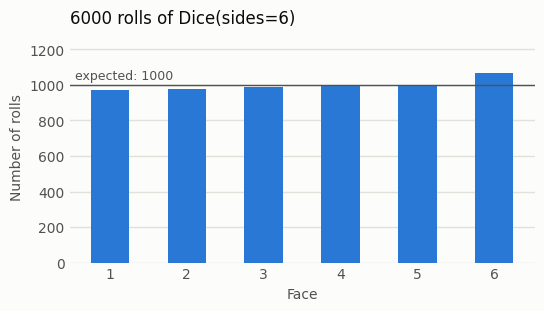

In [66]:
rolls = Counter(d6() for _ in range(6000))
faces = sorted(rolls)

fig, ax = plt.subplots(figsize=(6, 3))
style_axes(ax, grid_axis="y")
ax.bar(faces, [rolls[face] for face in faces], width=0.5, color=BLUE)
ax.axhline(1000, color=INK_2, linewidth=1)
ax.text(0.55, 1015, "expected: 1000", ha="left", va="bottom", color=INK_2, fontsize=9)
ax.set_ylim(0, 1300)
ax.set_xlabel("Face")
ax.set_ylabel("Number of rolls")
ax.set_title("6000 rolls of Dice(sides=6)", loc="left", color=INK)
plt.show()

## `Weapon` (task 3)

A `Weapon` has a `name` and a `damage_dice` (a `Dice`). This is **composition**: a weapon *has* a dice, and a character *has* a weapon. `roll_damage()` simply forwards to `damage_dice.roll()`, so the weapon decides *how* damage is rolled while the dice decides *what* is rolled.


In [67]:
sword = Weapon("Sword", Dice(sides=8))
show_class(Weapon, sword)

class Weapon
  constructor: Weapon(name: str, damage_dice: Task_2_Dice.Dice) -> None
  instance attributes (a leading _ means protected):
    name, damage_dice
  methods:
    - roll_damage
  special methods:
    - __repr__


In [68]:
print(repr(sword))
print("Ten damage rolls:" , [sword.roll_damage() for _ in range(10)])

Weapon(name='Sword', damage_dice=Dice(sides=8))
Ten damage rolls: [7, 7, 3, 2, 1, 4, 7, 3, 2, 3]


## `Character` (tasks 1 and 3)

`Character` is the extended version of the class from lecture 8. The main changes:

- **Encapsulation.** `_hp` is only changed by the character itself, through `take_damage()` and `heal()`. `attack()` no longer modifies `target._hp`; it asks the target to take damage instead. The public `hp` and `is_alive` are read-only properties.
- **HP stays between 0 and `hp_max`.** `take_damage()` stops at 0 and `heal()` stops at `hp_max`. Negative amounts raise a `ValueError`, and a dead character cannot be healed.
- **Weapons.** The constructor takes an optional `weapon`. A normal attack rolls the weapon's dice if there is one, and otherwise uses the base `damage`. This choice is made in the small helper `_roll_attack_damage()`, which subclasses can reuse.
- `take_damage()`, `heal()` and `attack()` return the number of HP that was actually lost or restored. This lets `Battle` log what happened using only public methods.

In [69]:
frodo = Character("Frodo", hp_max=100, damage=10)
show_class(Character, frodo)

class Character
  constructor: Character(name: str, hp_max: int = 100, damage: int = 10, weapon: Task_3_items.Weapon | None = None) -> None
  instance attributes (a leading _ means protected):
    name, _hp, hp_max, damage, weapon
  properties (read-only):
    - hp
    - is_alive
  methods:
    - take_damage
    - heal
    - attack
    - introduce
  special methods:
    - __repr__
    - __str__


In [70]:
print(frodo)         # __str__
print(repr(frodo))   # __repr__
frodo.introduce()

Character: Frodo with 100 HP and 10 damage
<Character name=Frodo hp=100 damage=10>
I am the mighty Frodo!


**Encapsulation in action.** The properties `hp` and `is_alive` cannot be assigned to from the outside:

In [71]:
for attribute in ("hp", "is_alive"):
    try:
        setattr(frodo, attribute, 50)
    except AttributeError as error:
        print(f"AttributeError when setting {attribute}: {error}")

AttributeError when setting hp: property 'hp' of 'Character' object has no setter
AttributeError when setting is_alive: property 'is_alive' of 'Character' object has no setter


**HP is always kept between 0 and `hp_max`:**

In [72]:
print("Start:   HP =", frodo.hp)
print("Lost", frodo.take_damage(30), "HP    -> HP =", frodo.hp)
print("Restored", frodo.heal(10), "HP -> HP =", frodo.hp)
print("Restored", frodo.heal(1000), "HP -> HP =", frodo.hp, f"(never above hp_max = {frodo.hp_max})")
print("Lost", frodo.take_damage(10_000), "HP -> HP =", frodo.hp, "| is_alive:", frodo.is_alive)
print("Restored", frodo.heal(50), "HP -> HP =", frodo.hp, "(a dead character cannot be healed)")

try:
    frodo.take_damage(-5)
except ValueError as error:
    print("ValueError:", error)

Start:   HP = 100
Lost 30 HP    -> HP = 70
Restored 10 HP -> HP = 80
Restored 20 HP -> HP = 100 (never above hp_max = 100)
Lost 100 HP -> HP = 0 | is_alive: False
Restored 0 HP -> HP = 0 (a dead character cannot be healed)
ValueError: Damage cannot be negative


**Attacking with and without a weapon.** An unarmed character always deals its base damage (10 here), while an armed character rolls the weapon's dice instead. The base damage is *not* added to the weapon roll.

In [73]:
dummy = Character("Training dummy", hp_max=10_000)
unarmed = Character("Unarmed", damage=10)
armed = Character("Armed", damage=10, weapon=Weapon("Sword", Dice(sides=8)))

print("Unarmed hits:", [unarmed.attack(dummy) for _ in range(8)])
print("Armed hits:  ", [armed.attack(dummy) for _ in range(8)])

Unarmed hits: [10, 10, 10, 10, 10, 10, 10, 10]
Armed hits:   [8, 1, 2, 2, 8, 3, 1, 7]


## `Warrior` (task 4)

A defensive specialist. `Warrior` inherits everything from `Character`, adds the attribute `armor` (default 5) and overrides `take_damage()`: the armor is subtracted from the incoming damage (never going below 0) before the damage is applied. The override reuses the parent's logic through `super().take_damage(...)`, so HP is still clamped at 0.

In the output below, the methods marked *inherited* are used unchanged from `Character`, while `take_damage` is overridden.

In [74]:
gimli = Warrior("Gimli", hp_max=120, armor=5)
show_class(Warrior, gimli)

class Warrior(Character)
  constructor: Warrior(name: str, hp_max: int = 100, damage: int = 10, weapon: Task_3_items.Weapon | None = None, armor: int = 5) -> None
  instance attributes (a leading _ means protected):
    name, _hp, hp_max, damage, weapon, armor
  properties (read-only):
    - hp  (inherited from Character)
    - is_alive  (inherited from Character)
  methods:
    - take_damage
    - heal  (inherited from Character)
    - attack  (inherited from Character)
    - introduce  (inherited from Character)
  special methods:
    - __repr__  (inherited from Character)
    - __str__  (inherited from Character)


In [75]:
print(f"{'incoming damage':>15} | {'Character loses':>15} | {'Warrior (armor 5) loses':>23}")
for incoming in (3, 5, 8, 20):
    plain, warrior = Character("Plain"), Warrior("Gimli")
    print(f"{incoming:>15} | {plain.take_damage(incoming):>15} | {warrior.take_damage(incoming):>23}")

incoming damage | Character loses | Warrior (armor 5) loses
              3 |               3 |                       0
              5 |               5 |                       0
              8 |               8 |                       3
             20 |              20 |                      15


## `Mage` (task 4)

A resource-based attacker with the attributes `mana` and `mana_max` (both default 30). `Mage` overrides `attack()`:

- **At least 10 mana:** spend 10 mana and cast a spell that deals **double the base damage**. The spell does not use any weapon, even if one is equipped.
- **Less than 10 mana:** fall back to the normal attack of `Character` (`super().attack()`, which uses the weapon if there is one) and restore 5 mana, never above `mana_max`.

The spell cost, the damage multiplier and the mana regeneration are class constants in the code. Mana is protected as `_mana` with a read-only property `mana`, just like HP, and is only changed by the mage itself.

In [76]:
gandalf = Mage("Gandalf", weapon=Weapon("Staff", Dice(sides=6)))
show_class(Mage, gandalf)

class Mage(Character)
  constructor: Mage(name: str, hp_max: int = 100, damage: int = 10, weapon: Task_3_items.Weapon | None = None, mana: int = 30, mana_max: int = 30) -> None
  instance attributes (a leading _ means protected):
    name, _hp, hp_max, damage, weapon, mana_max, _mana
  class constants:
    - SPELL_COST = 10
    - SPELL_MULTIPLIER = 2
    - MANA_REGEN = 5
  properties (read-only):
    - hp  (inherited from Character)
    - is_alive  (inherited from Character)
    - mana
  methods:
    - take_damage  (inherited from Character)
    - heal  (inherited from Character)
    - attack
    - introduce  (inherited from Character)
  special methods:
    - __repr__  (inherited from Character)
    - __str__  (inherited from Character)


The table below follows a mage with a staff (d6) through nine attacks on a training dummy. Spells deal 2 × 10 = 20 damage, the staff deals 1–6.

In [77]:
dummy = Character("Training dummy", hp_max=10_000)

print(f"{'attack':>6} | {'mana before':>11} | {'attack type':<11} | {'damage':>6} | {'mana after':>10}")
for number in range(1, 10):
    mana_before = gandalf.mana
    damage = gandalf.attack(dummy)
    kind = "spell" if mana_before >= Mage.SPELL_COST else "staff"
    print(f"{number:>6} | {mana_before:>11} | {kind:<11} | {damage:>6} | {gandalf.mana:>10}")

attack | mana before | attack type | damage | mana after
     1 |          30 | spell       |     20 |         20
     2 |          20 | spell       |     20 |         10
     3 |          10 | spell       |     20 |          0
     4 |           0 | staff       |      5 |          5
     5 |           5 | staff       |      4 |         10
     6 |          10 | spell       |     20 |          0
     7 |           0 | staff       |      3 |          5
     8 |           5 | staff       |      1 |         10
     9 |          10 | spell       |     20 |          0


The mage starts with enough mana for three spells in a row. After that, two staff attacks (each restoring 5 mana) are needed before the mana is back to 10, so from then on the mage casts a spell on every third attack.

## `Battle` (task 5)

`Battle` manages a turn-based fight between a `hero` and an `enemy`, which can be any `Character` (or subclass).

- `play_round()`: the hero attacks the enemy, and **only if the enemy is still alive** does the enemy strike back. This means the hero always has a small first-move advantage.
- `simulate_battle()`: plays rounds in a `while` loop until one of the characters is no longer alive, and returns the winner. We added a safety limit `max_rounds`: if two characters cannot hurt each other (for example two armored warriors with weak weapons), the loop would otherwise never end. In that case `None` is returned.
- `verbose=False` turns off the printed log, which is useful when simulating many battles.

`Battle` only uses the public interface of the characters (`attack()`, `hp`, `hp_max`, `is_alive`, `name`).

In [78]:
hero = Character("Boromin", hp_max=100, damage=10)
enemy = Character("Sauron", hp_max=100, damage=20)

battle = Battle(hero, enemy)
show_class(Battle, battle)

class Battle
  constructor: Battle(hero: Task_1_4_Characters.Character, enemy: Task_1_4_Characters.Character, verbose: bool = True) -> None
  instance attributes (a leading _ means protected):
    hero, enemy, verbose, rounds_played
  methods:
    - play_round
    - simulate_battle


**Playing single rounds:**

In [79]:
battle.play_round()
battle.play_round()
print("Rounds played so far:", battle.rounds_played)

--- Round 1 ---
Boromin hits Sauron for 10 damage (90/100 HP left)
Sauron hits Boromin for 20 damage (80/100 HP left)
--- Round 2 ---
Boromin hits Sauron for 10 damage (80/100 HP left)
Sauron hits Boromin for 20 damage (60/100 HP left)
Rounds played so far: 2


**If the hero defeats the enemy, the enemy does not get to strike back** (only one attack is logged):

In [80]:
strong = Character("Strong", damage=100)
weak = Character("Weak", hp_max=50, damage=10)

Battle(strong, weak).play_round()
print("Weak alive:", weak.is_alive, "| Strong HP:", strong.hp)

--- Round 1 ---
Strong hits Weak for 50 damage (0/50 HP left)
Weak alive: False | Strong HP: 100


**Simulating a whole battle:** Boromin hits for 10 and Sauron for 20, so Sauron needs 5 hits to win and Boromir needs 10. Boromir strikes first, but Sauron still wins.

In [81]:
battle = Battle(Character("Boromir", damage=10), Character("Sauron", damage=20))
winner = battle.simulate_battle()
print("Winner:", winner)

--- Round 1 ---
Boromir hits Sauron for 10 damage (90/100 HP left)
Sauron hits Boromir for 20 damage (80/100 HP left)
--- Round 2 ---
Boromir hits Sauron for 10 damage (80/100 HP left)
Sauron hits Boromir for 20 damage (60/100 HP left)
--- Round 3 ---
Boromir hits Sauron for 10 damage (70/100 HP left)
Sauron hits Boromir for 20 damage (40/100 HP left)
--- Round 4 ---
Boromir hits Sauron for 10 damage (60/100 HP left)
Sauron hits Boromir for 20 damage (20/100 HP left)
--- Round 5 ---
Boromir hits Sauron for 10 damage (50/100 HP left)
Sauron hits Boromir for 20 damage (0/100 HP left)
Sauron wins after 5 rounds!
Winner: Character: Sauron with 50 HP and 20 damage


## Simulated battles

We now let the three types of characters fight each other, first without and then with weapons. To get fresh characters for every battle we use small factory functions, since characters are damaged during a fight.

| Character | HP | Base damage | Special | Weapon (when armed) |
|---|---|---|---|---|
| Fighter (plain `Character`) | 100 | 10 | – | Greatsword, d20 |
| `Warrior` | 120 | 10 | armor 5 | Axe, d12 |
| `Mage` | 80 | 10 | 30 mana, spells deal 2 × 10 = 20 | Staff, d8 |

Remember that a weapon *replaces* the base damage, and that a mage's spells ignore the weapon.

In [82]:
def make_fighter(armed: bool) -> Character:
    """A plain Character, optionally with a Greatsword (d20)."""
    weapon = Weapon("Greatsword", Dice(sides=20)) if armed else None
    return Character("Aragorn", hp_max=100, damage=10, weapon=weapon)


def make_warrior(armed: bool) -> Warrior:
    """A Warrior with armor 5, optionally with an Axe (d12)."""
    weapon = Weapon("Axe", Dice(sides=12)) if armed else None
    return Warrior("Gimli", hp_max=120, damage=10, weapon=weapon, armor=5)


def make_mage(armed: bool) -> Mage:
    """A Mage with 30 mana, optionally with a Staff (d8)."""
    weapon = Weapon("Staff", Dice(sides=8)) if armed else None
    return Mage("Gandalf", hp_max=80, damage=10, weapon=weapon)


FACTORIES = {"Fighter": make_fighter, "Warrior": make_warrior, "Mage": make_mage}
MATCHUPS = [
    ("Fighter", "Warrior"),
    ("Fighter", "Mage"),
    ("Warrior", "Mage"),
    ("Mage", "Warrior"),
    ("Warrior", "Warrior"),
    ("Mage", "Mage"),
]


def run_battle(hero_type: str, enemy_type: str, armed: bool, verbose: bool = False):
    """Create fresh characters, let them fight, and return (winning side, rounds played)."""
    hero, enemy = FACTORIES[hero_type](armed), FACTORIES[enemy_type](armed)
    battle = Battle(hero, enemy, verbose=verbose)
    winner = battle.simulate_battle()
    side = "stalemate" if winner is None else ("hero" if winner is hero else "enemy")
    return side, battle.rounds_played

### Without weapons

Without weapons all damage is fixed, so there is no randomness at all: the same two characters always fight the same battle. We check this by repeating each battle 100 times.

In [83]:
print(f"{'Hero':<8} vs {'Enemy':<8} | {'winner':<7} | {'rounds':>6} | identical in 100 repeats?")
for hero_type, enemy_type in MATCHUPS:
    outcomes = {run_battle(hero_type, enemy_type, armed=False) for _ in range(100)}
    side, rounds = next(iter(outcomes))
    print(f"{hero_type:<8} vs {enemy_type:<8} | {side:<7} | {rounds:>6} | {len(outcomes) == 1}")

Hero     vs Enemy    | winner  | rounds | identical in 100 repeats?
Fighter  vs Warrior  | enemy   |     10 | True
Fighter  vs Mage     | enemy   |      6 | True
Warrior  vs Mage     | hero    |      8 | True
Mage     vs Warrior  | enemy   |      8 | True
Warrior  vs Warrior  | hero    |     24 | True
Mage     vs Mage     | hero    |      5 | True


Without weapons the outcome is decided purely by the fixed numbers: HP, damage, armor and the mage's mana.

- **Armor matters a lot.** A plain attack of 10 only does 10 − 5 = 5 damage to a Warrior, so the Fighter needs 24 hits to defeat him, while the Warrior needs just 10 hits to defeat the Fighter.
- **The Mage has high burst damage.** Its spells deal 20, and the Fighter loses to the Mage even though the Fighter has more HP.
- **The hero's first move is decisive between equals.** In the mirror matches (Warrior vs Warrior, Mage vs Mage) both sides need exactly the same number of attacks, so the hero, who attacks first, wins every time.

### With weapons: one battle

With weapons, the dice make every battle different. Here is a complete battle between the Fighter (Greatsword, d20) and the Mage (Staff, d8). Note how the mage's spells (20 damage) stand out from the staff attacks.

In [84]:
random.seed(7)
side, rounds = run_battle("Fighter", "Mage", armed=True, verbose=True)

--- Round 1 ---
Aragorn hits Gandalf for 11 damage (69/80 HP left)
Gandalf hits Aragorn for 20 damage (80/100 HP left)
--- Round 2 ---
Aragorn hits Gandalf for 5 damage (64/80 HP left)
Gandalf hits Aragorn for 20 damage (60/100 HP left)
--- Round 3 ---
Aragorn hits Gandalf for 13 damage (51/80 HP left)
Gandalf hits Aragorn for 20 damage (40/100 HP left)
--- Round 4 ---
Aragorn hits Gandalf for 2 damage (49/80 HP left)
Gandalf hits Aragorn for 2 damage (38/100 HP left)
--- Round 5 ---
Aragorn hits Gandalf for 18 damage (31/80 HP left)
Gandalf hits Aragorn for 2 damage (36/100 HP left)
--- Round 6 ---
Aragorn hits Gandalf for 12 damage (19/80 HP left)
Gandalf hits Aragorn for 20 damage (16/100 HP left)
--- Round 7 ---
Aragorn hits Gandalf for 19 damage (0/80 HP left)
Aragorn wins after 7 rounds!


### With weapons: 1000 battles per matchup

A single battle says little when dice are involved, so we simulate 1000 battles for each matchup (with fresh characters each time) and count who wins. The hero always attacks first, so we also include both orders of the Warrior–Mage matchup and the two mirror matches.

In [85]:
def win_rates(hero_type: str, enemy_type: str, armed: bool, n_battles: int = 1000) -> dict:
    """Simulate n_battles battles and return the share of hero wins, enemy wins and stalemates."""
    counts = Counter(run_battle(hero_type, enemy_type, armed)[0] for _ in range(n_battles))
    return {side: counts[side] / n_battles for side in ("hero", "enemy", "stalemate")}


random.seed(42)
N_BATTLES = 1000
results = {matchup: win_rates(*matchup, armed=True, n_battles=N_BATTLES) for matchup in MATCHUPS}

print(f"{'Hero':<8} vs {'Enemy':<8} | {'hero wins':>9} | {'enemy wins':>10} | {'stalemates':>10}")
for (hero_type, enemy_type), rates in results.items():
    print(
        f"{hero_type:<8} vs {enemy_type:<8} | {rates['hero']:>9.1%} | "
        f"{rates['enemy']:>10.1%} | {rates['stalemate']:>10.1%}"
    )

Hero     vs Enemy    | hero wins | enemy wins | stalemates
Fighter  vs Warrior  |     14.7% |      85.3% |       0.0%
Fighter  vs Mage     |     71.5% |      28.5% |       0.0%
Warrior  vs Mage     |     99.5% |       0.5% |       0.0%
Mage     vs Warrior  |      1.5% |      98.5% |       0.0%
Warrior  vs Warrior  |     52.6% |      47.4% |       0.0%
Mage     vs Mage     |    100.0% |       0.0% |       0.0%


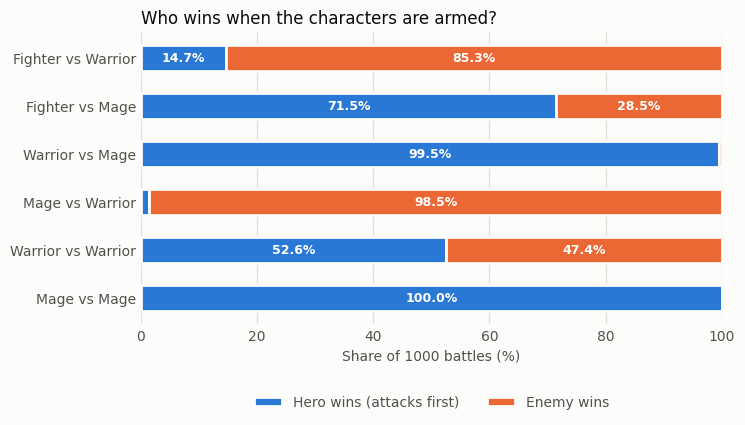

In [86]:
labels = [f"{hero_type} vs {enemy_type}" for hero_type, enemy_type in MATCHUPS]
hero_wins = [results[matchup]["hero"] * 100 for matchup in MATCHUPS]
enemy_wins = [results[matchup]["enemy"] * 100 for matchup in MATCHUPS]
rows = list(range(len(MATCHUPS)))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
style_axes(ax, grid_axis="x")
# A 2 px edge in the surface colour separates the touching segments
ax.barh(rows, hero_wins, height=0.55, color=BLUE, edgecolor=SURFACE, linewidth=2, label="Hero wins (attacks first)")
ax.barh(rows, enemy_wins, height=0.55, left=hero_wins, color=ORANGE, edgecolor=SURFACE, linewidth=2, label="Enemy wins")

# Print a percentage inside a segment only when it fits
for row, (hero_share, enemy_share) in enumerate(zip(hero_wins, enemy_wins)):
    if hero_share >= 9:
        ax.text(hero_share / 2, row, f"{hero_share:.1f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    if enemy_share >= 9:
        ax.text(hero_share + enemy_share / 2, row, f"{enemy_share:.1f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")

ax.set_yticks(rows)
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel(f"Share of {N_BATTLES} battles (%)")
ax.set_title("Who wins when the characters are armed?", loc="left", color=INK)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, labelcolor=INK_2)
plt.show()

Observations (the exact percentages change a little with another seed, but not the overall picture):

- **The Warrior is the strongest character in this setup.** He has the most HP, and armor 5 absorbs a large part of every hit: the Fighter's d20 greatsword averages 10.5, but only 6.0 gets through the armor on average. The Warrior beats the Fighter in most battles, and the Mage almost always, whichever of them attacks first.
- **The Mage depends on its spells.** Against armor 5, a staff attack (d8) does at most 3 damage, so only the spells (20 − 5 = 15 damage, every third attack) really hurt a Warrior.
- **Weapons change the outcome.** Without weapons the Mage beat the Fighter. With weapons the Fighter wins about 70% of the time, because a weapon *replaces* the base damage: the Greatsword (average 10.5) deals slightly more than the Fighter's base damage of 10, while the Staff (average 4.5) deals far less than the Mage's base damage of 10 whenever it is out of mana.
- **Mage vs Mage is decided by who moves first.** Four spells (4 × 20 = 80) are exactly enough to defeat an 80-HP mage, and the fourth spell is cast on the sixth attack. The dice are not involved in this, so the hero, who attacks first, always wins.
- **Warrior vs Warrior is almost a coin flip.** The damage that gets through the armor is small, so these battles are long, and the single extra attack the hero gets in the beginning barely matters.
- There are no stalemates in these matchups. They only happen if the weapons are too weak to get through the armor.

### A stalemate

Two warriors with daggers (d4) can never hurt each other: a roll of at most 4 is completely absorbed by armor 5. Without the `max_rounds` safety limit this battle would run forever. Here we stop after three rounds:

In [87]:
a = Warrior("Warrior A", weapon=Weapon("Dagger", Dice(sides=4)))
b = Warrior("Warrior B", weapon=Weapon("Dagger", Dice(sides=4)))

winner = Battle(a, b).simulate_battle(max_rounds=3)
print("Winner:", winner)

--- Round 1 ---
Warrior A hits Warrior B for 0 damage (100/100 HP left)
Warrior B hits Warrior A for 0 damage (100/100 HP left)
--- Round 2 ---
Warrior A hits Warrior B for 0 damage (100/100 HP left)
Warrior B hits Warrior A for 0 damage (100/100 HP left)
--- Round 3 ---
Warrior A hits Warrior B for 0 damage (100/100 HP left)
Warrior B hits Warrior A for 0 damage (100/100 HP left)
Stalemate after 3 rounds.
Winner: None


## Summary

- **Encapsulation:** HP (and mana) are protected attributes, only changed by the object itself, with read-only properties for the outside world. This keeps HP between 0 and `hp_max` no matter what other code does.
- **Composition:** `Weapon` has a `Dice`, and `Character` has an optional `Weapon`. Damage is decided by whichever object is responsible for it.
- **Inheritance and overriding:** `Warrior` overrides `take_damage()` and `Mage` overrides `attack()`. Both reuse the parent class with `super()`, and `Battle` works with all of them without knowing which type it has been given.
- **Simulation:** without weapons, battles are deterministic; with weapons, the dice make single battles unpredictable but the win rates over many battles are stable.